<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_EXP12_POSTLAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 26.4M/26.4M [00:01<00:00, 17.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 272kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 4.96MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.2MB/s]


Epoch: 1 Loss: 0.02120564877986908


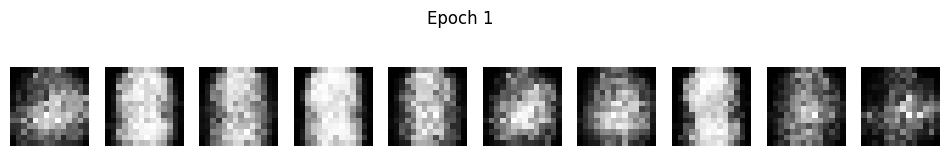

Epoch: 2 Loss: -0.02992737852036953


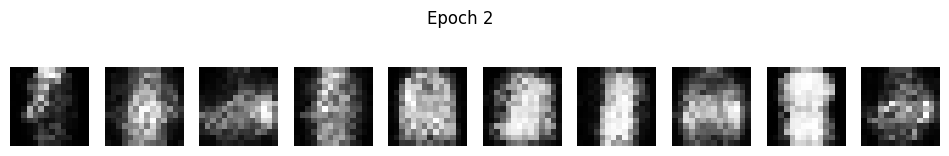

Epoch: 3 Loss: -0.014120888896286488


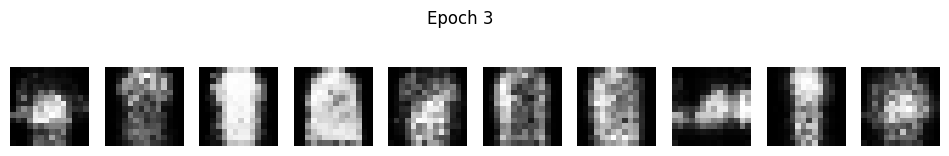

Epoch: 4 Loss: -0.0141462292522192


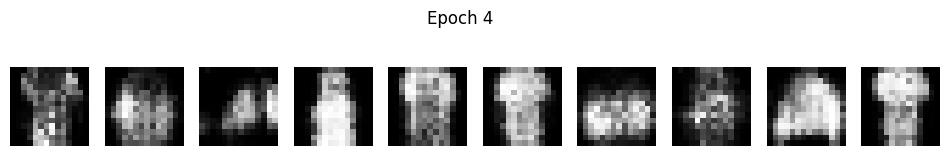

Epoch: 5 Loss: -0.012047667987644672


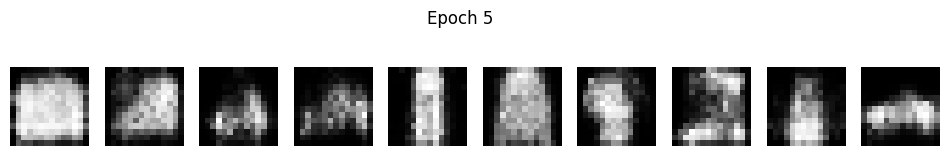

Training completed!


In [1]:

import torch
from torch import nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

# Dataset
transform = transforms.Compose([
    transforms.Resize((14, 14)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

data = datasets.FashionMNIST(
    "/content/data",
    download=True,
    transform=transform
)

loader = torch.utils.data.DataLoader(
    data, batch_size=64, shuffle=True, drop_last=True
)

# Generator
G = nn.Sequential(
    nn.Linear(32, 128),
    nn.ReLU(),
    nn.Linear(128, 196),
    nn.Tanh()
).to(device)

# Discriminator
D = nn.Sequential(
    nn.Linear(196, 128),
    nn.LeakyReLU(0.2),
    nn.Linear(128, 1)
).to(device)

og = torch.optim.Adam(
    G.parameters(), lr=0.0002, betas=(0.5, 0.9)
)

od = torch.optim.Adam(
    D.parameters(), lr=0.0002, betas=(0.5, 0.9)
)

# Generate images
def generate_images(epoch):
    G.eval()

    with torch.no_grad():
        z = torch.randn(10, 32, device=device)
        images = G(z).cpu().reshape(10, 14, 14)

    fig, axes = plt.subplots(1, 10, figsize=(12, 2))

    for i, ax in enumerate(axes):
        ax.imshow((images[i] + 1) / 2, cmap="gray")
        ax.axis("off")

    plt.suptitle("Epoch " + str(epoch))
    plt.show()

    G.train()

# Training
for epoch in range(1, 6):

    for x, labels in loader:
        x = x.to(device).flatten(1)
        n = len(x)

        # Train critic
        fake = G(torch.randn(n, 32, device=device)).detach()

        loss_d = D(fake).mean() - D(x).mean()

        od.zero_grad()
        loss_d.backward()
        od.step()

        # Weight clipping
        with torch.no_grad():
            for p in D.parameters():
                p.clamp_(-0.01, 0.01)

        # Train generator
        fake = G(torch.randn(n, 32, device=device))
        loss_g = -D(fake).mean()

        og.zero_grad()
        loss_g.backward()
        og.step()

    print("Epoch:", epoch, "Loss:", loss_g.item())

    generate_images(epoch)

print("Training completed!")
